In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import requests
import os
import scipy.stats as stats
from dotenv import load_dotenv
from coingecko_sdk import Coingecko

In [25]:
from datetime import datetime, timedelta, timezone
import pandas as pd
import os
import numpy as np
from coingecko_sdk import Coingecko



class DataExtractor:
    """
        Extracts and processes Bitcoin price data.
        
        Attributes:
            None
    """
    def __init__(self) -> None:
        self.API_KEY  = os.getenv("COINGECKO_API_KEY")
        self.BASE_URL = "https://api.coingecko.com/api/v3"
        self.client = Coingecko(demo_api_key=self.API_KEY, environment="demo")
     
    def _fetch_data(self):
        now = datetime.now(timezone.utc)
        start = now - timedelta(days=(364))

        response = self.client.coins.market_chart.get_range(
            "bitcoin",
            vs_currency="usd",
            from_=str(int(start.timestamp())),
            to=str(int(now.timestamp())),
        )

        data = response.model_dump() if hasattr(response, "model_dump") else response

        df = pd.DataFrame(data["prices"], columns=["timestamp", "price"])
        df["market_cap"] = [x[1] for x in data["market_caps"]]
        df["total_volume"] = [x[1] for x in data["total_volumes"]]
        df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
        df = df.set_index("timestamp")
        return df
    def _preprocess_data(self, df):
        """
        Preprocesses the data by adding log price, price difference, log price difference, price change, and volatility.
        
        Args:
            df (pd.DataFrame): The input DataFrame containing price data.
            
        Returns:
            pd.DataFrame: The DataFrame with added features.
        """
        df["log_price"] = np.log(df["price"])
        df['price_diff'] = df['price'].diff()
        df['log_price_diff'] = df['log_price'].diff()
        df['box_cox'] = stats.boxcox(df['price'])[0]
        df['box_cox_diff'] = df['box_cox'].diff(periods=12)
        df["price_change"] = df["price"].pct_change()
        df["volatility"] = df["price_change"].rolling(window=30).std()
        df = df.drop(columns =["log_price","market_cap","price_diff","box_cox"])
        return df
    def _get_loader(self,df):
        pass

In [27]:
data = DataExtractor()._fetch_data()

In [28]:
data_processed = DataExtractor()._preprocess_data(data)
data_processed.head()

,price,total_volume,log_price_diff,box_cox_diff,price_change,volatility
timestamp,,,,,,
2025-10-25,111030.183379,4.887219e+10,NaN,NaN,NaN,NaN
2025-10-26,111631.637265,2.313449e+10,0.005402,NaN,0.005417,NaN
2025-10-27,114419.221697,4.275006e+10,0.024665,NaN,0.024971,NaN
2025-10-28,114085.331238,6.359007e+10,-0.002922,NaN,-0.002918,NaN
2025-10-29,112893.852036,6.636450e+10,-0.010499,NaN,-0.010444,NaN


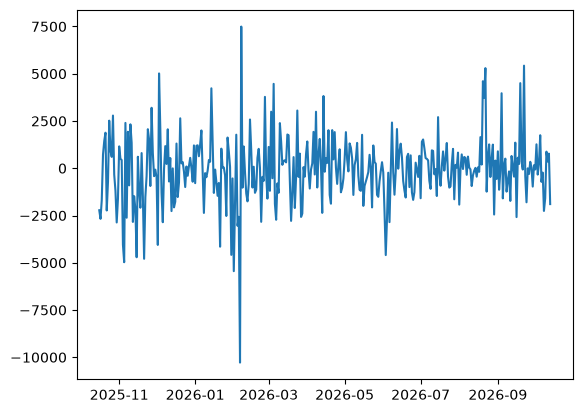

In [ ]:
import matplotlib.pyplot as plt


plt.plot(data['price_diff'])
plt.show()

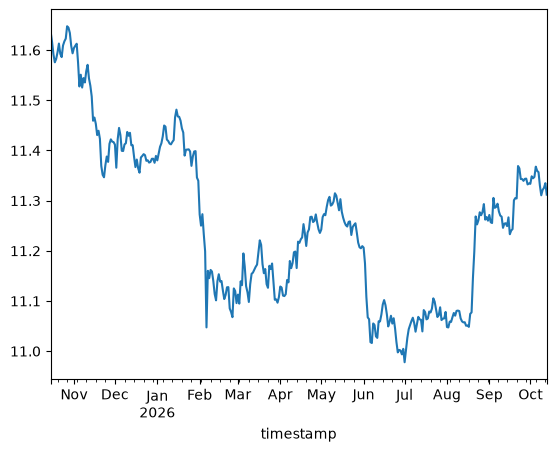

In [ ]:
#Inspecting Log_transform_price

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


data_processed["log_price"] = np.log(data_processed["price"])
data_processed["log_price"].plot()
plt.show()


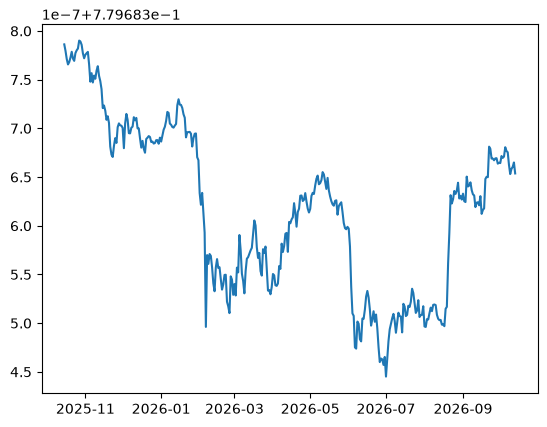

In [ ]:
#Boxcox Transformation

from scipy import stats

data_processed["log_price"] = np.log(data["price"])
data_processed["boxcox_price"], _ = stats.boxcox(data["price"])
plt.plot(data_processed["boxcox_price"])
plt.show()

<Axes: xlabel='timestamp'>

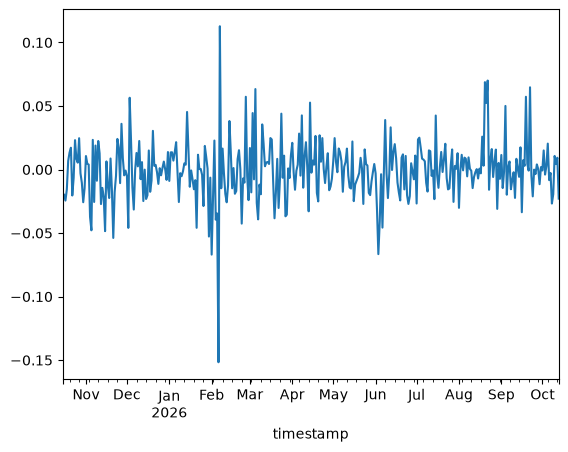

In [ ]:
data_processed['log_price_diff'].plot()

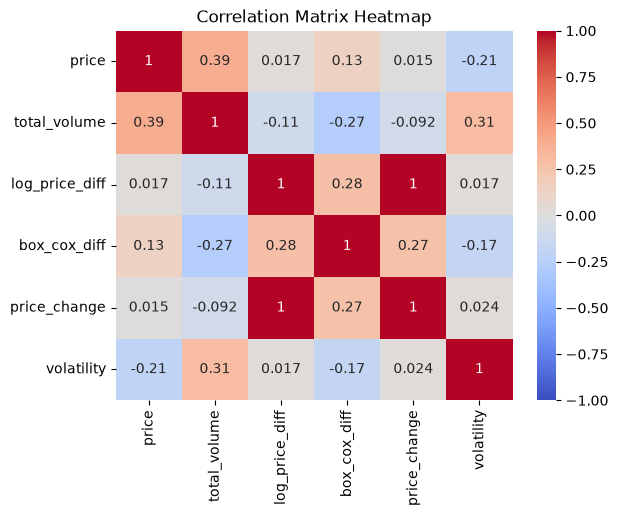

In [ ]:
import seaborn as sns

correlation_matrix = data_processed.corr()

sns.heatmap(correlation_matrix, 
            annot=True,       # Display correlation values
            cmap='coolwarm',  # Color scheme
            vmin=-1, vmax=1,  # Standardize color scale
            center=0)         # Center white at zero

plt.title('Correlation Matrix Heatmap')
plt.show()